In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from networkx.algorithms.isomorphism.matchhelpers import numerical_doc
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings

warnings.filterwarnings("ignore")

In [45]:
model_df = pd.read_csv("../EDA/final_model.csv")

In [46]:
X = model_df.drop(['Runs', 'Ground', 'Start Date'], axis=1)
y = model_df['Runs']

In [47]:
X.head()

,Pos,Inns,NotOut,Rolling5,Rolling10,Opposition_v Australia,Opposition_v Bangladesh,Opposition_v England,Opposition_v Ireland,Opposition_v Netherlands,Opposition_v New Zealand,Opposition_v Pakistan,Opposition_v South Africa,Opposition_v Sri Lanka,Opposition_v U.A.E.,Opposition_v West Indies,Opposition_v Zimbabwe
0,2,2,0,12.000000,12.000000,0,0,0,0,0,0,0,0,1,0,0,0
1,1,1,0,24.500000,24.500000,0,0,0,0,0,0,0,0,1,0,0,0
2,1,1,0,24.666667,24.666667,0,0,0,0,0,0,0,0,1,0,0,0
3,1,2,0,32.000000,32.000000,0,0,0,0,0,0,0,0,1,0,0,0
4,7,1,1,31.800000,31.800000,0,0,0,0,0,0,0,0,1,0,0,0


# Train-test split

In [48]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

# Feature Scaling

In [49]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

In [50]:
X_test_scaled

,Pos,Inns,NotOut,Rolling5,Rolling10,Opposition_v Australia,Opposition_v Bangladesh,Opposition_v England,Opposition_v Ireland,Opposition_v Netherlands,Opposition_v New Zealand,Opposition_v Pakistan,Opposition_v South Africa,Opposition_v Sri Lanka,Opposition_v U.A.E.,Opposition_v West Indies,Opposition_v Zimbabwe
238,-0.332478,0.880976,-0.442696,-0.057814,-0.201389,2.294157,-0.230429,-0.379777,-0.092057,-0.064957,-0.350202,-0.240370,-0.342594,-0.482867,-0.064957,-0.435890,-0.160817
239,-0.332478,0.880976,-0.442696,-0.607115,-0.773408,2.294157,-0.230429,-0.379777,-0.092057,-0.064957,-0.350202,-0.240370,-0.342594,-0.482867,-0.064957,-0.435890,-0.160817
240,-0.332478,-1.135104,-0.442696,-0.607115,-0.250595,2.294157,-0.230429,-0.379777,-0.092057,-0.064957,-0.350202,-0.240370,-0.342594,-0.482867,-0.064957,-0.435890,-0.160817
241,-0.332478,-1.135104,-0.442696,-0.491473,0.136902,-0.435890,-0.230429,2.633122,-0.092057,-0.064957,-0.350202,-0.240370,-0.342594,-0.482867,-0.064957,-0.435890,-0.160817
242,-0.332478,-1.135104,-0.442696,-0.096362,-0.041469,-0.435890,-0.230429,2.633122,-0.092057,-0.064957,-0.350202,-0.240370,-0.342594,-0.482867,-0.064957,-0.435890,-0.160817
243,-0.332478,-1.135104,-0.442696,0.452939,0.266068,-0.435890,-0.230429,2.633122,-0.092057,-0.064957,-0.350202,-0.240370,-0.342594,-0.482867,-0.064957,-0.435890,-0.160817
244,-0.332478,0.880976,-0.442696,0.318023,-0.170635,-0.435890,-0.230429,-0.379777,-0.092057,-0.064957,-0.350202,-0.240370,2.918904,-0.482867,-0.064957,-0.435890,-0.160817
245,-0.332478,-1.135104,-0.442696,-0.048178,-0.404363,-0.435890,-0.230429,-0.379777,-0.092057,-0.064957,-0.350202,-0.240370,2.918904,-0.482867,-0.064957,-0.435890,-0.160817
246,-0.332478,0.880976,-0.442696,-0.655299,-0.718051,-0.435890,-0.230429,-0.379777,-0.092057,-0.064957,-0.350202,-0.240370,2.918904,-0.482867,-0.064957,-0.435890,-0.160817
247,-0.332478,0.880976,-0.442696,-0.568568,-0.410514,-0.435890,-0.230429,-0.379777,-0.092057,-0.064957,-0.350202,-0.240370,-0.342594,-0.482867,-0.064957,2.294157,-0.160817


In [51]:
model = LinearRegression()

In [52]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [53]:
y_pred = model.predict(X_test)

In [54]:
y_pred

array([ 47.26092801,  45.71867535,  46.84932121,  36.82803429,
        37.55826516,  38.93052228,  46.27612582,  46.13744679,
        43.84298727,  51.84014513,  51.43560521,  51.65041992,
        33.12958877,  33.27348858,  43.75970961,  57.46136825,
        43.27917826,  41.6559768 ,  43.30696119,  82.75300935,
        51.01778856,  50.24546695,  48.98166822,  46.99363339,
        47.73684757,  44.24729514,  34.78791671,  73.37323507,
        43.53654077,  46.596963  ,  46.67726083, 105.99850313,
        37.4497629 ,  86.05976396,  48.71982528,  40.36771333,
        45.04069332,  87.28464319,  31.75791963,  50.40492909,
        51.41366492,  47.72967872,  46.28828826,  44.48758943,
        36.88260634,  35.01344772,  45.21812343,  72.36356616,
        46.84730712,  46.02333198,  47.20657824,  47.05493964,
        46.50670869,  82.75655752,  44.09415776,  45.65904482,
        86.30387812,  50.14683593,  52.83020331,  51.03208868])

In [55]:
MAE = mean_absolute_error(y_test, y_pred)
MSE = mean_squared_error(y_test, y_pred)
RMSE = mean_squared_error(y_test, y_pred) ** 0.5
R2 = r2_score(y_test, y_pred)

n = X_test.shape[0]
p = X_test.shape[1]

adjusted_r2 = (1 - ((1 - R2) * (n - 1)) // (n - p - 1))

In [56]:
print("MAE: ", MAE)
print("MSE: ", MSE)
print("RMSE: ", RMSE)
print("R2: ", R2)
print("adjusted_r2: ", adjusted_r2)

MAE:  35.345737401270554
MSE:  1610.0506554536707
RMSE:  40.125436514182255
R2:  0.14451786041243464
adjusted_r2:  0.0


In [57]:
y_train

0      37
1      25
2      54
3      31
4       2
       ..
233    78
234    89
235    51
236    15
237     9
Name: Runs, Length: 238, dtype: int64

# Training using Scaled df

In [58]:
scaled_model = LinearRegression()
scaled_model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [59]:
y_pred_scaled = scaled_model.predict(X_test_scaled)
y_pred_scaled

array([ 47.26092801,  45.71867535,  46.84932121,  36.82803429,
        37.55826516,  38.93052228,  46.27612582,  46.13744679,
        43.84298727,  51.84014513,  51.43560521,  51.65041992,
        33.12958877,  33.27348858,  43.75970961,  57.46136825,
        43.27917826,  41.6559768 ,  43.30696119,  82.75300935,
        51.01778856,  50.24546695,  48.98166822,  46.99363339,
        47.73684757,  44.24729514,  34.78791671,  73.37323507,
        43.53654077,  46.596963  ,  46.67726083, 105.99850313,
        37.4497629 ,  86.05976396,  48.71982528,  40.36771333,
        45.04069332,  87.28464319,  31.75791963,  50.40492909,
        51.41366492,  47.72967872,  46.28828826,  44.48758943,
        36.88260634,  35.01344772,  45.21812343,  72.36356616,
        46.84730712,  46.02333198,  47.20657824,  47.05493964,
        46.50670869,  82.75655752,  44.09415776,  45.65904482,
        86.30387812,  50.14683593,  52.83020331,  51.03208868])

In [60]:
MAE_scaled = mean_absolute_error(y_test, y_pred_scaled)
MSE_scaled = mean_squared_error(y_test, y_pred_scaled)
RMSE_scaled = mean_squared_error(y_test, y_pred_scaled) ** 0.5
R2_scaled = r2_score(y_test, y_pred_scaled)

n_scaled = X_test_scaled.shape[0]
p_scaled = X_test_scaled.shape[1]

adjusted_r2_scaled = (1 - ((1 - R2) * (n_scaled - 1)) // (n_scaled - p_scaled - 1))

In [61]:
print("MAE: ", MAE_scaled)
print("MSE: ", MSE_scaled)
print("RMSE: ", RMSE_scaled)
print("R2: ", R2_scaled)
print("adjusted_r2: ", adjusted_r2_scaled)

MAE:  35.34573740127054
MSE:  1610.0506554536705
RMSE:  40.125436514182255
R2:  0.14451786041243475
adjusted_r2:  0.0


# Model gave bad results, therefore adding more featues

In [62]:
model_df['PrevRuns'] = model_df['Runs'].shift(1)

In [63]:
model_df['Rolling3'] = (model_df['Runs'].rolling(3, min_periods=1).mean().shift(1))

In [64]:
model_df

,Runs,Pos,Inns,Ground,Start Date,NotOut,Rolling5,Rolling10,Opposition_v Australia,Opposition_v Bangladesh,...,Opposition_v Netherlands,Opposition_v New Zealand,Opposition_v Pakistan,Opposition_v South Africa,Opposition_v Sri Lanka,Opposition_v U.A.E.,Opposition_v West Indies,Opposition_v Zimbabwe,PrevRuns,Rolling3
0,37,2,2,Dambulla,2008-08-20,0,12.000000,12.000000,0,0,...,0,0,0,0,1,0,0,0,NaN,NaN
1,25,1,1,Colombo (RPS),2008-08-24,0,24.500000,24.500000,0,0,...,0,0,0,0,1,0,0,0,37.0,37.000000
2,54,1,1,Colombo (RPS),2008-08-27,0,24.666667,24.666667,0,0,...,0,0,0,0,1,0,0,0,25.0,31.000000
3,31,1,2,Colombo (RPS),2008-08-29,0,32.000000,32.000000,0,0,...,0,0,0,0,1,0,0,0,54.0,38.666667
4,2,7,1,Colombo (RPS),2009-09-14,1,31.800000,31.800000,0,0,...,0,0,0,0,1,0,0,0,31.0,36.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,102,3,1,Raipur,2025-12-03,0,42.000000,47.900000,0,0,...,0,0,0,1,0,0,0,0,135.0,69.666667
294,65,3,2,Visakhapatnam,2025-12-06,1,62.200000,52.900000,0,0,...,0,0,0,1,0,0,0,0,102.0,103.666667
295,93,3,2,Vadodara,2026-01-11,0,75.200000,57.200000,0,0,...,0,1,0,0,0,0,0,0,65.0,100.666667
296,23,3,1,Rajkot,2026-01-14,0,93.800000,56.500000,0,0,...,0,1,0,0,0,0,0,0,93.0,86.666667


In [65]:
model_df['CareerAvg'] = (model_df['Runs'].expanding().mean().shift(1))
model_df

,Runs,Pos,Inns,Ground,Start Date,NotOut,Rolling5,Rolling10,Opposition_v Australia,Opposition_v Bangladesh,...,Opposition_v New Zealand,Opposition_v Pakistan,Opposition_v South Africa,Opposition_v Sri Lanka,Opposition_v U.A.E.,Opposition_v West Indies,Opposition_v Zimbabwe,PrevRuns,Rolling3,CareerAvg
0,37,2,2,Dambulla,2008-08-20,0,12.000000,12.000000,0,0,...,0,0,0,1,0,0,0,NaN,NaN,NaN
1,25,1,1,Colombo (RPS),2008-08-24,0,24.500000,24.500000,0,0,...,0,0,0,1,0,0,0,37.0,37.000000,37.000000
2,54,1,1,Colombo (RPS),2008-08-27,0,24.666667,24.666667,0,0,...,0,0,0,1,0,0,0,25.0,31.000000,31.000000
3,31,1,2,Colombo (RPS),2008-08-29,0,32.000000,32.000000,0,0,...,0,0,0,1,0,0,0,54.0,38.666667,38.666667
4,2,7,1,Colombo (RPS),2009-09-14,1,31.800000,31.800000,0,0,...,0,0,0,1,0,0,0,31.0,36.666667,36.750000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,102,3,1,Raipur,2025-12-03,0,42.000000,47.900000,0,0,...,0,0,1,0,0,0,0,135.0,69.666667,49.071672
294,65,3,2,Visakhapatnam,2025-12-06,1,62.200000,52.900000,0,0,...,0,0,1,0,0,0,0,102.0,103.666667,49.251701
295,93,3,2,Vadodara,2026-01-11,0,75.200000,57.200000,0,0,...,1,0,0,0,0,0,0,65.0,100.666667,49.305085
296,23,3,1,Rajkot,2026-01-14,0,93.800000,56.500000,0,0,...,1,0,0,0,0,0,0,93.0,86.666667,49.452703


In [66]:
model_df.columns

Index(['Runs', 'Pos', 'Inns', 'Ground', 'Start Date', 'NotOut', 'Rolling5',
       'Rolling10', 'Opposition_v Australia', 'Opposition_v Bangladesh',
       'Opposition_v England', 'Opposition_v Ireland',
       'Opposition_v Netherlands', 'Opposition_v New Zealand',
       'Opposition_v Pakistan', 'Opposition_v South Africa',
       'Opposition_v Sri Lanka', 'Opposition_v U.A.E.',
       'Opposition_v West Indies', 'Opposition_v Zimbabwe', 'PrevRuns',
       'Rolling3', 'CareerAvg'],
      dtype='str')

In [67]:
model_df = model_df.drop('Rolling5',axis=1)

In [68]:
model_df['Inns'].value_counts()

Inns
2    164
1    134
Name: count, dtype: int64

In [69]:
ground_avg = (model_df.groupby('Ground')['Runs'].mean())

model_df['GroundAvg'] = model_df['Ground'].map(ground_avg)

In [70]:
model_df

,Runs,Pos,Inns,Ground,Start Date,NotOut,Rolling10,Opposition_v Australia,Opposition_v Bangladesh,Opposition_v England,...,Opposition_v Pakistan,Opposition_v South Africa,Opposition_v Sri Lanka,Opposition_v U.A.E.,Opposition_v West Indies,Opposition_v Zimbabwe,PrevRuns,Rolling3,CareerAvg,GroundAvg
0,37,2,2,Dambulla,2008-08-20,0,12.000000,0,0,0,...,0,0,1,0,0,0,NaN,NaN,NaN,25.666667
1,25,1,1,Colombo (RPS),2008-08-24,0,24.500000,0,0,0,...,0,0,1,0,0,0,37.0,37.000000,37.000000,54.000000
2,54,1,1,Colombo (RPS),2008-08-27,0,24.666667,0,0,0,...,0,0,1,0,0,0,25.0,31.000000,31.000000,54.000000
3,31,1,2,Colombo (RPS),2008-08-29,0,32.000000,0,0,0,...,0,0,1,0,0,0,54.0,38.666667,38.666667,54.000000
4,2,7,1,Colombo (RPS),2009-09-14,1,31.800000,0,0,0,...,0,0,1,0,0,0,31.0,36.666667,36.750000,54.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,102,3,1,Raipur,2025-12-03,0,47.900000,0,0,0,...,0,1,0,0,0,0,135.0,69.666667,49.071672,56.500000
294,65,3,2,Visakhapatnam,2025-12-06,1,52.900000,0,0,0,...,0,1,0,0,0,0,102.0,103.666667,49.251701,81.500000
295,93,3,2,Vadodara,2026-01-11,0,57.200000,0,0,0,...,0,0,0,0,0,0,65.0,100.666667,49.305085,62.000000
296,23,3,1,Rajkot,2026-01-14,0,56.500000,0,0,0,...,0,0,0,0,0,0,93.0,86.666667,49.452703,46.000000


In [71]:
model_df['PrevRuns'] = model_df['PrevRuns'].fillna(0)
model_df['Rolling3'] = model_df['Rolling3'].fillna(0)
model_df['CareerAvg'] = model_df['CareerAvg'].fillna(0)

In [72]:
X_new = model_df.drop(['Runs', 'Ground', 'Start Date','NotOut'], axis=1)
y_new = model_df['Runs']

In [73]:
X_train, X_test, y_train, y_test = train_test_split(X_new,y_new,test_size=0.2,random_state=42)

In [74]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

In [75]:
X_train_scaled

,Pos,Inns,Rolling10,Opposition_v Australia,Opposition_v Bangladesh,Opposition_v England,Opposition_v Ireland,Opposition_v Netherlands,Opposition_v New Zealand,Opposition_v Pakistan,Opposition_v South Africa,Opposition_v Sri Lanka,Opposition_v U.A.E.,Opposition_v West Indies,Opposition_v Zimbabwe,PrevRuns,Rolling3,CareerAvg,GroundAvg
6,1.481738,0.903767,-1.511406,-0.442696,-0.259354,-0.365148,-0.092057,-0.092057,-0.394132,-0.25,-0.319142,-0.462910,-0.064957,2.449490,-0.146490,-0.773770,-1.296008,-3.385827,0.093168
182,-0.238524,0.903767,0.127622,-0.442696,-0.259354,-0.365148,-0.092057,-0.092057,-0.394132,-0.25,-0.319142,2.160247,-0.064957,-0.408248,-0.146490,-1.052515,0.624909,0.196122,-1.959874
170,-0.238524,-1.106480,1.095007,-0.442696,-0.259354,-0.365148,-0.092057,-0.092057,-0.394132,4.00,-0.319142,-0.462910,-0.064957,-0.408248,-0.146490,0.132150,0.469159,0.151498,-0.091623
146,-0.238524,0.903767,-0.394767,-0.442696,-0.259354,-0.365148,-0.092057,-0.092057,-0.394132,-0.25,-0.319142,-0.462910,-0.064957,-0.408248,6.826419,-0.123366,-0.504279,-0.072527,-1.429802
30,-0.238524,0.903767,-1.336355,2.258886,-0.259354,-0.365148,-0.092057,-0.092057,-0.394132,-0.25,-0.319142,-0.462910,-0.064957,-0.408248,-0.146490,-0.285967,-1.347925,-1.491106,1.505376
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
188,-0.238524,0.903767,0.495228,2.258886,-0.259354,-0.365148,-0.092057,-0.092057,-0.394132,-0.25,-0.319142,-0.462910,-0.064957,-0.408248,-0.146490,-0.495026,-0.374487,0.289278,-0.986756
71,-0.238524,0.903767,0.127622,-0.442696,-0.259354,-0.365148,-0.092057,-0.092057,-0.394132,-0.25,-0.319142,2.160247,-0.064957,-0.408248,-0.146490,-0.425339,-0.192779,-0.828092,-0.065854
106,-0.238524,0.903767,-0.562447,-0.442696,-0.259354,-0.365148,-0.092057,-0.092057,-0.394132,-0.25,-0.319142,-0.462910,-0.064957,-0.408248,6.826419,-0.820228,-0.231716,-0.464234,0.323393
270,-0.238524,0.903767,-0.239985,-0.442696,-0.259354,-0.365148,-0.092057,-0.092057,-0.394132,4.00,-0.319142,-0.462910,-0.064957,-0.408248,-0.146490,0.132150,0.611930,0.814501,-0.948781


In [76]:
model = LinearRegression()
model.fit(X_train_scaled, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [77]:
coef_df = pd.DataFrame({
    'Feature': X_new.columns,
    'Coefficient': model.coef_
})

coef_df.sort_values(
    by='Coefficient',
    ascending=False
)

,Feature,Coefficient
18,GroundAvg,21.302283
2,Rolling10,3.915419
1,Inns,1.899261
16,Rolling3,1.314417
0,Pos,-0.789105
17,CareerAvg,-0.837537
15,PrevRuns,-2.041260
6,Opposition_v Ireland,-2.279585
7,Opposition_v Netherlands,-2.525004
12,Opposition_v U.A.E.,-2.917438


In [78]:
y_pred_new = model.predict(X_test_scaled)
y_pred_new

array([ 37.65817005,  11.54601897, 105.38689217,  37.19437821,
       132.48508259,  27.65696546,  64.99023399,  40.75545563,
        52.89415107,  38.76632647,  45.03052184,  52.67786843,
        51.72279695,  40.35413733,  19.62248924,  19.56469063,
        37.59107442,  64.69306746,  54.10906488,  39.61805854,
        36.31497297,  40.18875988,  83.43884811,  48.42128005,
        10.4996921 ,  19.33283726,  60.93849543,  61.88426532,
        37.25215445,  56.92951966,  63.37214096,  19.23335784,
        58.49966968,  33.50068903,  54.82597587,  56.71265561,
        88.33628531,  60.48168559,  29.80327223,  32.56750067,
        33.99377022,  58.39608635,  40.73928252,  24.98173039,
        45.38433515,  53.54540941,  45.88838471,  43.46861249,
        55.99844526,  11.69385367,  56.82584983,  44.53664995,
        62.61223437,  33.41667984,  59.8197694 ,  51.52098076,
        68.88281663,  22.06049661,  56.72664579,  34.2302044 ])

In [79]:
MAE_new = mean_absolute_error(y_test, y_pred_new)
MSE_new = mean_squared_error(y_test, y_pred_new)
RMSE_new = mean_squared_error(y_test, y_pred_new) ** 0.5
R2_new = r2_score(y_test, y_pred_new)

n_new = X_train_scaled.shape[0]
p_new = X_train_scaled.shape[1]

adjusted_r2_new = (1 - ((1 - R2_new) * (n_new - 1)) / (n_new - p_new - 1))

In [80]:
print("MAE new: ", MAE_new)
print("MSE new: ", MSE_new)
print("RMSE new: ", RMSE_new)
print("R2 new: ", R2_new)
print("adjusted_r2 new: ", adjusted_r2_new)

MAE new:  32.96152398872862
MSE new:  1622.061810135661
RMSE new:  40.27482849293912
R2 new:  0.1814726347948088
adjusted_r2 new:  0.1101330937906867


In [81]:
X_test_scaled.shape

(60, 19)

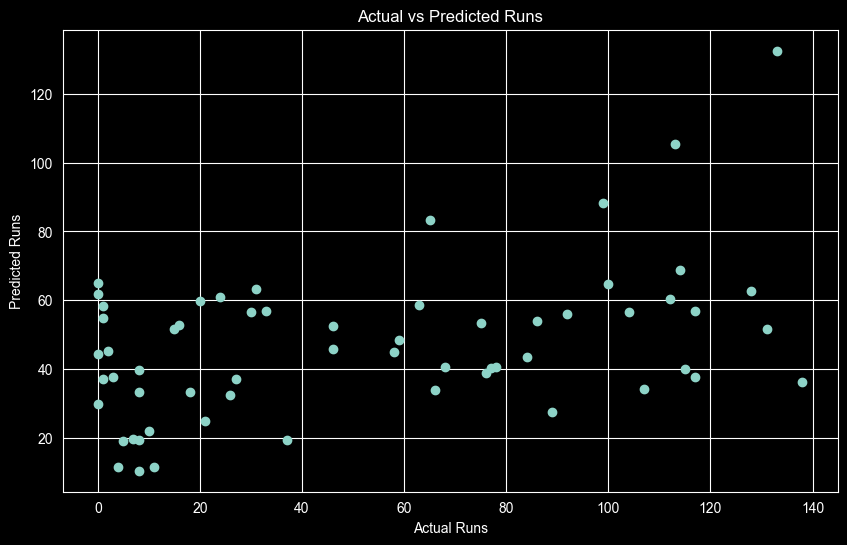

In [82]:
plt.figure(figsize=(10,6))
plt.scatter(y_test, y_pred_new)
plt.xlabel("Actual Runs")
plt.ylabel("Predicted Runs")
plt.title("Actual vs Predicted Runs")
plt.show()

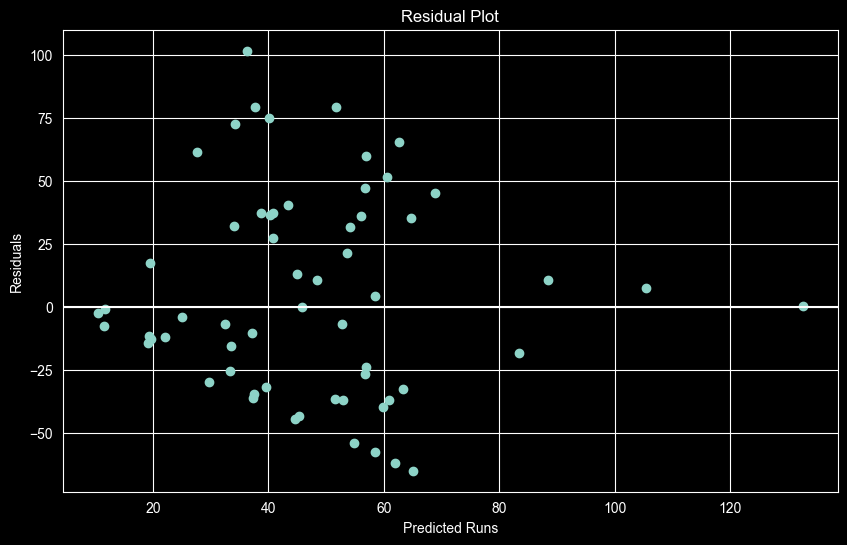

In [83]:
residuals = y_test - y_pred_new

plt.figure(figsize=(10,6))
plt.scatter(y_pred_new, residuals)
plt.axhline(y=0)
plt.xlabel("Predicted Runs")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()